<div style="text-align: center; font-family: 'Helvetica', sans-serif;">

# **Trabajo Práctico 2: Reconstrucción 3D**


</div>

In [1]:
import os, glob, json, pickle
import cv2
import numpy as np
import matplotlib.pyplot as plt
from i308_utils import imshow, show_images, np_print

<div style="text-align: center; font-family: 'Helvetica', sans-serif;">

### **Carga de la calibración estéreo**
</div>

Usamos la calibración que hicimos con la herramienta `calib-stereo` de la cátedra a 1280x720.
La herramienta guarda dos archivos: `stereo_calibration.pkl` (intrínsecos, distorsión y `R`, `T` entre cámaras)
y `stereo_maps.pkl` (mapas de rectificación, `R1`, `R2`, `P1`, `P2` y `Q`).

In [2]:
# Rutas del proyecto (el notebook corre desde notebooks/)
BASE = "." if os.path.isdir("datasets") else ".."

calib_file = os.path.join(BASE, "calibration", "stereo_calibration.pkl")
maps_file = os.path.join(BASE, "calibration", "stereo_maps.pkl")
captures_dir = os.path.join(BASE, "datasets", "stereo_stitch_charuco", "captures")
rect_dir = os.path.join(BASE, "datasets", "stereo_stitch_charuco", "rect")

with open(calib_file, "rb") as f:
    calibration = pickle.load(f)
with open(maps_file, "rb") as f:
    maps = pickle.load(f)

left_K, left_dist = calibration["left_K"], calibration["left_dist"]
right_K, right_dist = calibration["right_K"], calibration["right_dist"]
R, T = calibration["R"], calibration["T"]
P1, P2, Q = maps["P1"], maps["P2"], maps["Q"]

print(f"Tamaño de imagen: {calibration['image_size']}")
print(f"Baseline: {np.linalg.norm(T):.2f} mm")
print("left_K =", np_print(left_K))

Tamaño de imagen: (1280, 720)
Baseline: 60.17 mm
left_K = np.array([
	[   403.150,	     0.000,	   635.809],
	[     0.000,	   400.555,	   356.209],
	[     0.000,	     0.000,	     1.000]
])


<div style="text-align: center; font-family: 'Helvetica', sans-serif;">

### **Error de reproyección de la calibración**
</div>

La herramienta `calib-stereo` mostró el RMS de la calibración solo por consola y no lo guardó en el `.pkl`.
Para reportarlo, repetimos la calibración estéreo con las mismas fotos del checkerboard (`datasets/calib/`, 30 pares)
usando `cv2.stereoCalibrate`, como en el Tutorial 6. El tablero tiene 10x7 casilleros, es decir 9x6 esquinas internas.
Si los parámetros que obtenemos coinciden con los del `.pkl`, el RMS es el de nuestra calibración.

In [3]:
from utils import read_img, numero

CHECKERBOARD = (9, 6)    # esquinas internas (tablero de 10x7 casilleros)
SQUARE_MM = 28.0         # inferido del baseline del pkl, a confirmar con regla (no afecta el RMS, que está en px)

calib_dir = os.path.join(BASE, "datasets", "calib")

# Puntos del tablero en el mundo (z = 0), en mm
board_points = np.zeros((CHECKERBOARD[0] * CHECKERBOARD[1], 3), np.float32)
board_points[:, :2] = np.mgrid[0:CHECKERBOARD[0], 0:CHECKERBOARD[1]].T.reshape(-1, 2) * SQUARE_MM

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 1e-3)
world_points, left_points, right_points = [], [], []

for lf in sorted(glob.glob(os.path.join(calib_dir, "left_*.jpg")), key=numero):
    idx = numero(lf)
    gray_l = cv2.cvtColor(read_img(lf), cv2.COLOR_BGR2GRAY)
    gray_r = cv2.cvtColor(read_img(os.path.join(calib_dir, f"right_{idx}.jpg")), cv2.COLOR_BGR2GRAY)

    found_l, corners_l = cv2.findChessboardCorners(gray_l, CHECKERBOARD)
    found_r, corners_r = cv2.findChessboardCorners(gray_r, CHECKERBOARD)
    if not (found_l and found_r):
        print(f"Par {idx}: tablero no detectado en ambas imágenes")
        continue

    left_points.append(cv2.cornerSubPix(gray_l, corners_l, (7, 7), (-1, -1), criteria))
    right_points.append(cv2.cornerSubPix(gray_r, corners_r, (7, 7), (-1, -1), criteria))
    world_points.append(board_points)

# Calibración estéreo
rms_stereo, K1, D1, K2, D2, R_cal, T_cal, E_cal, F_cal = cv2.stereoCalibrate(
    world_points, left_points, right_points, None, None, None, None, calibration["image_size"], flags=0
)

print(f"Pares usados: {len(world_points)}")
print(f"RMS de reproyección estéreo: {rms_stereo:.3f} px")
print(f"fx izquierda: {K1[0, 0]:.2f} px (pkl: {left_K[0, 0]:.2f} px)")
print(f"fx derecha: {K2[0, 0]:.2f} px (pkl: {right_K[0, 0]:.2f} px)")
print(f"Baseline: {np.linalg.norm(T_cal):.2f} mm (pkl: {np.linalg.norm(T):.2f} mm)")

Par 7: tablero no detectado en ambas imágenes
Pares usados: 29
RMS de reproyección estéreo: 1.248 px
fx izquierda: 402.05 px (pkl: 403.15 px)
fx derecha: 400.82 px (pkl: 401.72 px)
Baseline: 60.18 mm (pkl: 60.17 mm)


Usamos 29 de los 30 pares: en el par 7, `findChessboardCorners` no detecta el tablero en la imagen izquierda, probablemente por un reflejo de la luz sobre los casilleros del centro. Como la calibración estéreo necesita las esquinas en ambas imágenes de cada par, ese par se descarta completo. Con 29 pares tenemos de sobra (en la tutorial se recomienda más de 20).

<div style="text-align: center; font-family: 'Helvetica', sans-serif;">

### **Rectificación estéreo**
</div>

Aplicamos los mapas de rectificación con `cv2.remap`. Si la rectificación es correcta, un mismo punto
de la escena queda en la misma fila en ambas imágenes, así que trazamos líneas horizontales para verificarlo.

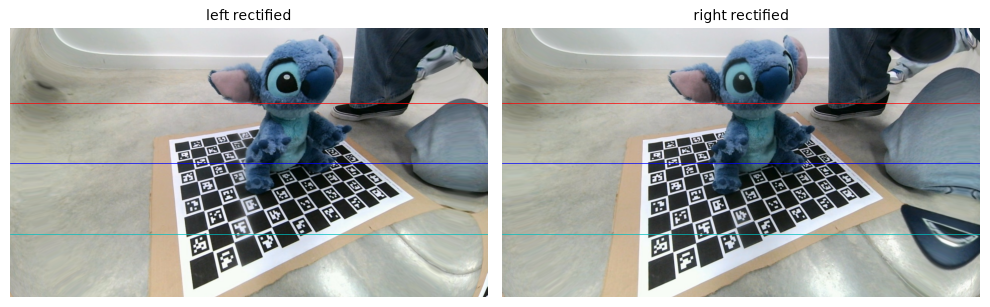

In [4]:
from utils import read_img

i = 13
left = read_img(os.path.join(captures_dir, f"left_{i}.jpg"))
right = read_img(os.path.join(captures_dir, f"right_{i}.jpg"))

left_rect = cv2.remap(left, maps["left_map_x"], maps["left_map_y"], cv2.INTER_LINEAR)
right_rect = cv2.remap(right, maps["right_map_x"], maps["right_map_y"], cv2.INTER_LINEAR)

fig, axes = show_images([left_rect, right_rect], ["left rectified", "right rectified"], show=False)
for y, c in zip([200, 360, 550], ["r", "b", "c"]):
    axes[0].axhline(y=y, color=c, linewidth=0.5)
    axes[1].axhline(y=y, color=c, linewidth=0.5)
plt.show()

Rectificamos los 27 pares y los guardamos en PNG (sin compresión con pérdida) para usarlos en `stereodemo`.

In [5]:
from utils import read_img, write_img, numero

os.makedirs(rect_dir, exist_ok=True)
left_files = sorted(glob.glob(os.path.join(captures_dir, "left_*.jpg")), key=numero)

for lf in left_files:
    idx = numero(lf)
    rf = os.path.join(captures_dir, f"right_{idx}.jpg")
    left_rect = cv2.remap(read_img(lf), maps["left_map_x"], maps["left_map_y"], cv2.INTER_LINEAR)
    right_rect = cv2.remap(read_img(rf), maps["right_map_x"], maps["right_map_y"], cv2.INTER_LINEAR)
    write_img(os.path.join(rect_dir, f"rect_left_{idx}.png"), left_rect)
    write_img(os.path.join(rect_dir, f"rect_right_{idx}.png"), right_rect)

print(f"Pares rectificados: {len(left_files)}")

Pares rectificados: 27


La herramienta `stereodemo` no lee los `.pkl`: necesita un `stereodemo_calibration.json` en la carpeta de pares
rectificados con la cámara **ya rectificada** (focal y centro de `P1`/`P2`, baseline en metros). Con esto corremos
`stereodemo datasets/stereo_stitch_charuco/rect` para ajustar los parámetros de disparidad a mano.

In [6]:
h, w = left_rect.shape[:2]
calib_json = {
    "width": w, "height": h,
    "baseline_meters": float(np.linalg.norm(T)) / 1000,
    "fx": float(P1[0, 0]), "fy": float(P1[1, 1]),
    "cx0": float(P1[0, 2]), "cx1": float(P2[0, 2]), "cy": float(P1[1, 2]),
    "depth_range": [0.2, 3.0],
    "left_image_rect_normalized": [0, 0, 1, 1],
}
with open(os.path.join(rect_dir, "stereodemo_calibration.json"), "w") as f:
    json.dump(calib_json, f, indent=2)

calib_json

{'width': 1280,
 'height': 720,
 'baseline_meters': 0.06016896206128554,
 'fx': 405.88681301544904,
 'fy': 405.88681301544904,
 'cx0': 631.0462799072266,
 'cx1': 631.0462799072266,
 'cy': 352.4043731689453,
 'depth_range': [0.2, 3.0],
 'left_image_rect_normalized': [0, 0, 1, 1]}

<div style="text-align: center; font-family: 'Helvetica', sans-serif;">

### **Tablero ChArUco**
</div>

El tablero de nuestras capturas **no es** el `5x7 / DICT_6X6_250` del ejemplo de la cátedra. Su geometría está
impresa en el borde del propio tablero:

> `Charuco Board | Dict: DICT_5X5_100 | Grid: 9x13 | Square: 42.0mm | Marker: 31.5mm`

Es decir, 9 casilleros en x por 13 en y, con 58 marcadores (IDs 0 a 57, que es justo lo que se detecta) y
8 x 12 = 96 esquinas internas. Todo el pipeline queda en **milímetros**.

Para la pose usamos `solvePnP` con `SOLVEPNP_IPPE` (específico para puntos coplanares), refinamos con
Levenberg-Marquardt y descartamos iterativamente las esquinas mal detectadas (función `estimate_pose` en `utils.py`).

In [7]:
# Definimos el tablero
ARUCO_DICT = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_5X5_100)
SQUARES = (9, 13)        # (x, y)
SQUARE_MM, MARKER_MM = 42.0, 31.5

board = cv2.aruco.CharucoBoard(SQUARES, SQUARE_MM, MARKER_MM, ARUCO_DICT)
charuco_detector = cv2.aruco.CharucoDetector(board)
corners3d_board = board.getChessboardCorners()   # (96, 3) en mm, z = 0
N_CORNERS_X = SQUARES[0] - 1

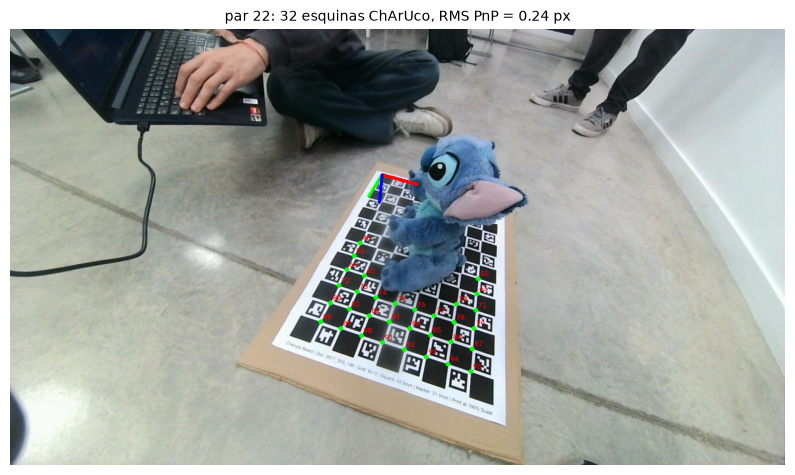

In [8]:
from utils import detect_charuco, estimate_pose

# Probamos la detección y la pose en un par
img0 = read_img(os.path.join(captures_dir, "left_22.jpg"))
det0 = detect_charuco(img0, charuco_detector)
pose0 = estimate_pose(img0, left_K, left_dist, charuco_detector, corners3d_board)

vis = img0.copy()
for k, (u, v) in det0.items():
    cv2.circle(vis, (int(u), int(v)), 4, (0, 255, 0), -1)
    cv2.putText(vis, str(k), (int(u) + 4, int(v) - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 255), 1)
cv2.drawFrameAxes(vis, left_K, left_dist, pose0["rvec"], pose0["tvec"], 120, 3)

imshow(vis, title=f"par 22: {len(det0)} esquinas ChArUco, RMS PnP = {pose0['rms']:.2f} px", figsize=(10, 6))

<div style="text-align: center; font-family: 'Helvetica', sans-serif;">

### **Verificación de la calibración**
</div>

El `.pkl` de la tool no guarda el RMS de la calibración. Para tener una medida de calidad usamos el tablero como dato
**independiente** de la calibración:

1. **Error de reproyección estéreo**: en cada par estimamos la pose del tablero con la cámara izquierda (`solvePnP`),
   la llevamos a la cámara derecha con los extrínsecos `R, T` de la calibración y reproyectamos las esquinas.
   Si `K`, `dist`, `R` y `T` son correctos, el error en la derecha es chico.
2. **Escala métrica**: triangulamos las esquinas detectadas en ambas imágenes con `P1`, `P2` y medimos la distancia
   entre esquinas vecinas, que debería ser 42,0 mm.

In [9]:
from utils import square_sides, rms

R1, R2 = maps["R1"], maps["R2"]
err_left, err_right, square_dists = [], [], []

for lf in left_files:
    idx = numero(lf)
    imgL = read_img(lf)
    imgR = read_img(os.path.join(captures_dir, f"right_{idx}.jpg"))

    dL, dR = detect_charuco(imgL, charuco_detector), detect_charuco(imgR, charuco_detector)
    common = sorted(set(dL) & set(dR))
    pose = estimate_pose(imgL, left_K, left_dist, charuco_detector, corners3d_board)
    if pose is None or len(common) < 8:
        print(f"Par {idx}: tablero no detectado en ambas imágenes")
        continue

    X = corners3d_board[common].astype(np.float64)
    pl = np.array([dL[k] for k in common])
    pr = np.array([dR[k] for k in common])

    # Reproyección izquierda (pose propia) y derecha (pose izquierda + R, T de la calibración)
    projL, _ = cv2.projectPoints(X, pose["rvec"], pose["tvec"], left_K, left_dist)
    Rl, _ = cv2.Rodrigues(pose["rvec"])
    rv_r, _ = cv2.Rodrigues(R @ Rl)
    projR, _ = cv2.projectPoints(X, rv_r, R @ pose["tvec"] + T, right_K, right_dist)

    eL = np.linalg.norm(projL.reshape(-1, 2) - pl, axis=1)
    eR = np.linalg.norm(projR.reshape(-1, 2) - pr, axis=1)
    good = eL < 2.0                      # mismas esquinas que aceptó el PnP
    err_left += list(eL[good])
    err_right += list(eR[good])

    # Triangulación en el marco rectificado y lado del casillero
    ul = cv2.undistortPoints(pl.reshape(-1, 1, 2), left_K, left_dist, R=R1, P=P1).reshape(-1, 2)
    ur = cv2.undistortPoints(pr.reshape(-1, 1, 2), right_K, right_dist, R=R2, P=P2).reshape(-1, 2)
    Xh = cv2.triangulatePoints(P1, P2, ul.T, ur.T)
    Xt = (Xh[:3] / Xh[3]).T

    d = square_sides(Xt, common, good, N_CORNERS_X)
    square_dists += d

    lado = f"{np.median(d):.2f} mm" if d else "-"
    print(f"Par {idx}: {len(common)} esquinas, error derecha = {eR[good].mean():.2f} px, "
          f"dy rect = {np.median(ul[:, 1] - ur[:, 1]):.2f} px, lado = {lado}")

print()
print(f"RMS de reproyección izquierda (PnP): {rms(err_left):.3f} px")
print(f"RMS de reproyección derecha (vía R, T): {rms(err_right):.3f} px")
print(f"Lado del casillero triangulado: mediana {np.median(square_dists):.2f} mm, "
      f"media {np.mean(square_dists):.2f} ± {np.std(square_dists):.2f} mm (real 42,0 mm)")

Par 0: 17 esquinas, error derecha = 1.85 px, dy rect = -1.42 px, lado = 41.79 mm
Par 1: tablero no detectado en ambas imágenes
Par 2: 26 esquinas, error derecha = 1.37 px, dy rect = -1.05 px, lado = 41.77 mm
Par 3: 28 esquinas, error derecha = 1.49 px, dy rect = -1.27 px, lado = 41.50 mm
Par 4: 32 esquinas, error derecha = 1.35 px, dy rect = -1.21 px, lado = 41.83 mm
Par 5: 31 esquinas, error derecha = 1.26 px, dy rect = -1.03 px, lado = 42.54 mm
Par 6: 19 esquinas, error derecha = 1.86 px, dy rect = -1.52 px, lado = 41.50 mm
Par 7: 35 esquinas, error derecha = 1.79 px, dy rect = -1.21 px, lado = 41.32 mm
Par 8: 41 esquinas, error derecha = 1.20 px, dy rect = -0.89 px, lado = 41.64 mm
Par 9: 27 esquinas, error derecha = 1.18 px, dy rect = -0.95 px, lado = 41.93 mm
Par 10: 38 esquinas, error derecha = 0.83 px, dy rect = -0.82 px, lado = 42.26 mm
Par 11: 19 esquinas, error derecha = 1.15 px, dy rect = -1.04 px, lado = 42.13 mm
Par 12: 42 esquinas, error derecha = 0.97 px, dy rect = -0.76

El error en la cámara derecha (≈1,3 px) mide de forma conjunta los intrínsecos y los extrínsecos `R, T`. El lado del
casillero triangulado da ≈42,1 mm frente a 42,0 mm reales (≈0,3 %), así que **la calibración es métrica**: la escala de
toda la reconstrucción viene del baseline `T` en mm. El `dy rect` muestra un desfasaje vertical residual de 0,2 a 1,8 px
entre imágenes rectificadas, siempre del mismo signo y mayor en los pares 0 a 7 (tablero en el borde de la imagen).
Es aceptable para SGBM y es un punto para la discusión: recalibrar cubriendo mejor los bordes lo bajaría.

<div style="text-align: center; font-family: 'Helvetica', sans-serif;">

### **Disparidad con SGBM**
</div>

Usamos `StereoSGBM` de OpenCV. Los parámetros dependen de la cámara y de la escena, no de cada foto, así que los
fijamos una vez para los 27 pares (los ajustamos antes en `stereodemo`, ver `imgs/`):

| parámetro | valor | por qué |
|---|---|---|
| `minDisparity`, `numDisparities` | 8, 144 | busca d en [8, 152) px. Con z = f·B/d ≈ 24 400/d mm cubre de ~16 cm a ~3 m; el peluche está entre 25 y 60 cm (d ≈ 40 a 100 px) |
| `blockSize` | 5 | ventana chica: conserva bordes (orejas) y el peluche tiene textura suficiente |
| `P1`, `P2` | 8·3·5², 32·3·5² | penalidades de suavidad recomendadas por OpenCV (P2 > P1 penaliza saltos grandes) |
| `uniquenessRatio` | 10 | descarta matches ambiguos |
| `speckleWindowSize`, `speckleRange` | 200, 2 | elimina manchas chicas inconsistentes |
| `disp12MaxDiff` | 1 | chequeo izquierda-derecha |
| `mode` | `SGBM_3WAY` | más rápido que `HH` con calidad similar |

In [10]:
SGBM_PARAMS = dict(
    minDisparity=8,
    numDisparities=144,
    blockSize=5,
    P1=8 * 3 * 5 ** 2,
    P2=32 * 3 * 5 ** 2,
    disp12MaxDiff=1,
    uniquenessRatio=10,
    speckleWindowSize=200,
    speckleRange=2,
    preFilterCap=63,
    mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY,
)
sgbm = cv2.StereoSGBM_create(**SGBM_PARAMS)

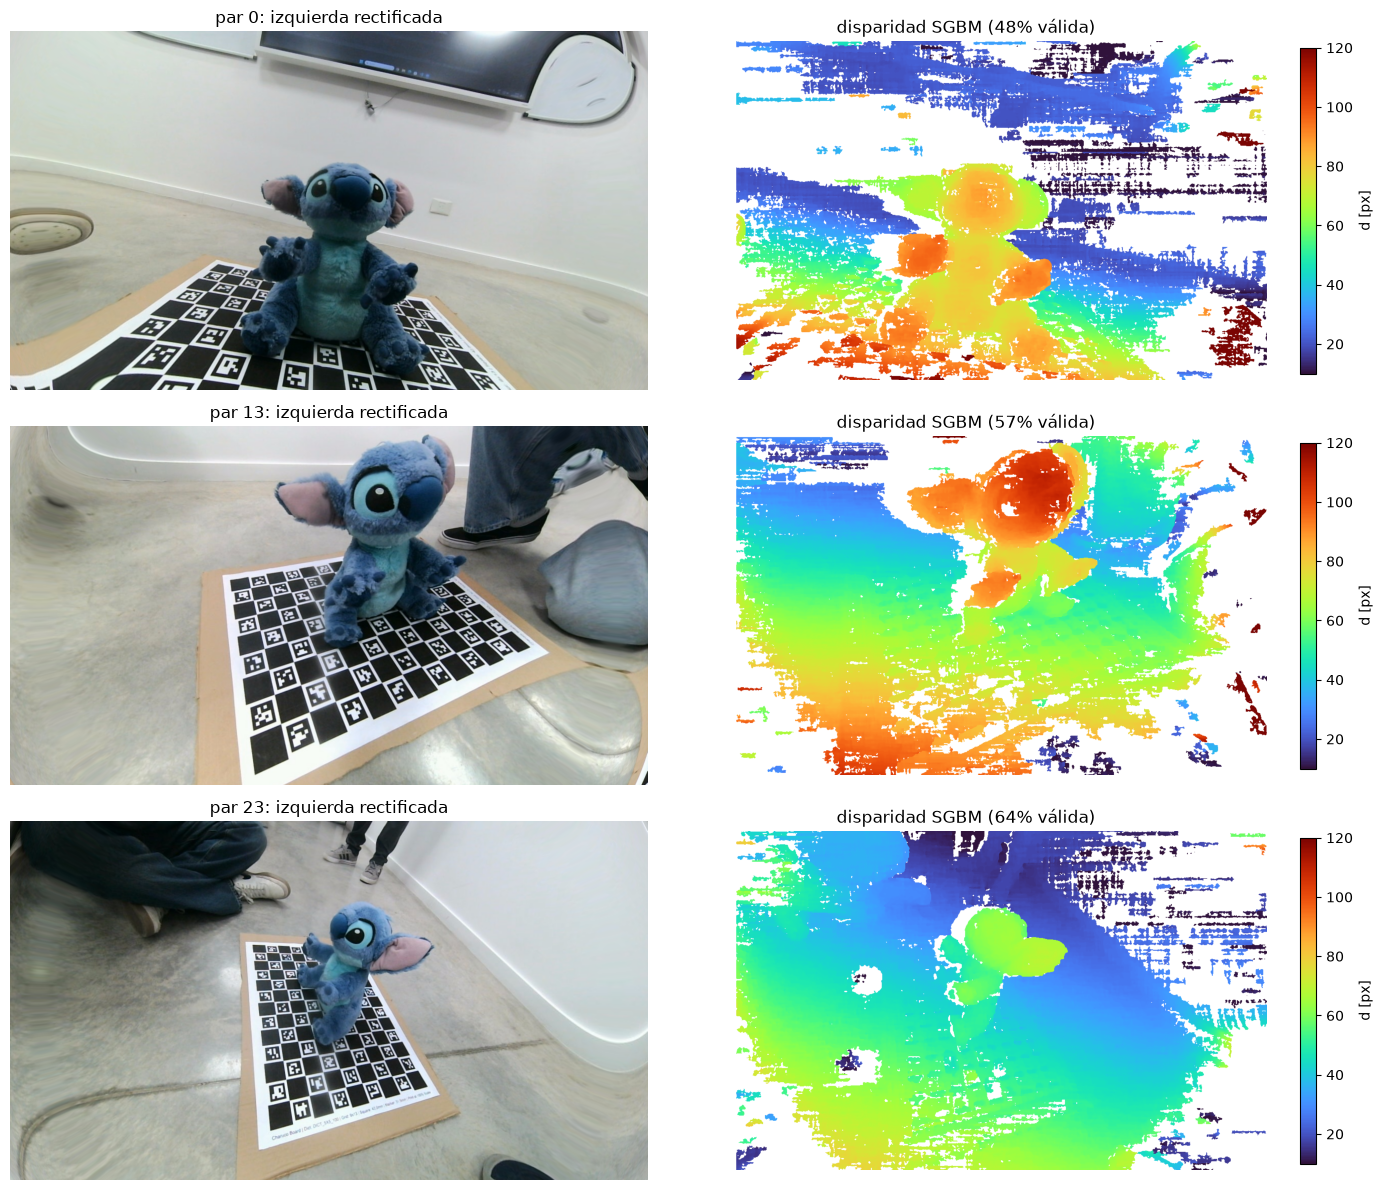

In [11]:
from utils import rectify_pair, compute_disparity

# Disparidad de tres pares representativos
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for row, idx in enumerate([0, 13, 23]):
    _, lr, rr = rectify_pair(idx, captures_dir, maps)
    disp = compute_disparity(sgbm, lr, rr, SGBM_PARAMS["minDisparity"])

    axes[row, 0].imshow(lr[:, :, ::-1])
    axes[row, 0].set_title(f"par {idx}: izquierda rectificada")

    im = axes[row, 1].imshow(disp, cmap="turbo", vmin=10, vmax=120)
    axes[row, 1].set_title(f"disparidad SGBM ({np.isfinite(disp).mean():.0%} válida)")
    fig.colorbar(im, ax=axes[row, 1], fraction=0.025, label="d [px]")

    for a in axes[row]:
        a.axis("off")

plt.tight_layout()
plt.show()

<div style="text-align: center; font-family: 'Helvetica', sans-serif;">

### **Nube de puntos local**
</div>

`cv.reprojectImageTo3D(disp, Q)` aplica, para cada píxel, $[X\ Y\ Z\ W]^T = Q\,[u\ v\ d\ 1]^T$ y devuelve
$(X/W, Y/W, Z/W)$. Con nuestra `Q` eso es exactamente

$$Z = \frac{f\,B}{d},\qquad X = \frac{(u-c_x)\,Z}{f},\qquad Y = \frac{(v-c_y)\,Z}{f}$$

con $f = 405{,}9$ px y $B = 60{,}17$ mm, en el sistema de la **cámara izquierda rectificada** y en mm.

Antes de pasar a 3D filtramos por píxel: disparidad válida, profundidad entre 150 y 1000 mm (fuera de eso es fondo
del aula o ruido) y **bordes de profundidad**: en los saltos de disparidad SGBM interpola entre frente y fondo y genera
"flying pixels" (el halo gris alrededor de las orejas), así que descartamos los píxeles donde la disparidad varía más
de 3 px en un vecindario de 5x5.

In [12]:
from utils import local_cloud

idx = 13
_, lr, rr = rectify_pair(idx, captures_dir, maps)
disp = compute_disparity(sgbm, lr, rr, SGBM_PARAMS["minDisparity"])
X_loc, C_loc, mask = local_cloud(disp, lr, Q)

print(f"Par {idx}: {len(X_loc)} puntos locales ({mask.mean():.0%} de los píxeles)")

# Chequeo de la fórmula z = f·B/d en un píxel cualquiera
v, u = np.argwhere(mask)[len(X_loc) // 2]
f, B = P1[0, 0], -P2[0, 3] / P1[0, 0]
print(f"Píxel ({u}, {v}): d = {disp[v, u]:.2f} px, f·B/d = {f * B / disp[v, u]:.1f} mm, "
      f"z de reprojectImageTo3D = {cv2.reprojectImageTo3D(disp, Q)[v, u, 2]:.1f} mm")

Par 13: 400729 puntos locales (43% de los píxeles)
Píxel (470, 343): d = 55.00 px, f·B/d = 444.0 mm, z de reprojectImageTo3D = 444.0 mm


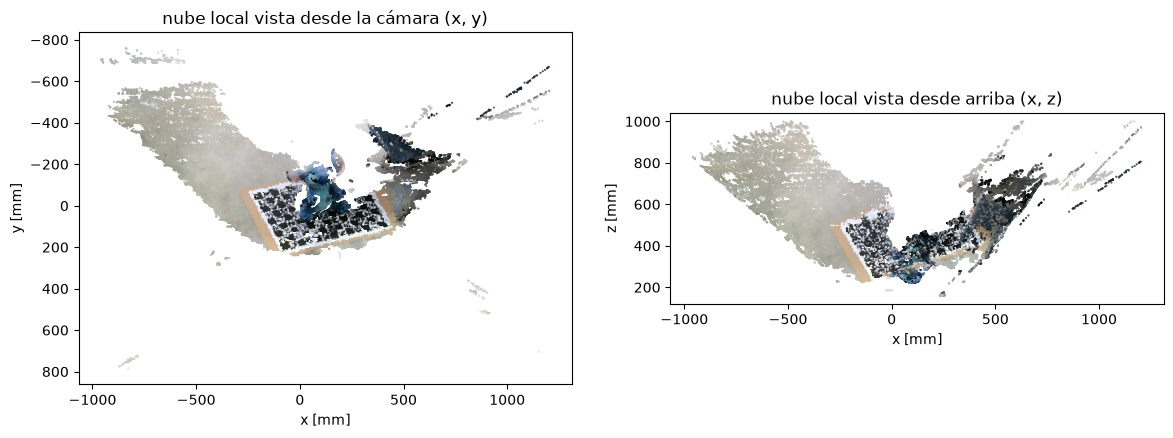

In [13]:
sub = np.random.default_rng(0).choice(len(X_loc), min(150_000, len(X_loc)), replace=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(X_loc[sub, 0], X_loc[sub, 1], c=C_loc[sub], s=0.2)
ax[0].invert_yaxis()
ax[0].set_title("nube local vista desde la cámara (x, y)")
ax[0].set_aspect("equal")

ax[1].scatter(X_loc[sub, 0], X_loc[sub, 2], c=C_loc[sub], s=0.2)
ax[1].set_title("nube local vista desde arriba (x, z)")
ax[1].set_aspect("equal")

for a in ax:
    a.set_xlabel("x [mm]")
ax[0].set_ylabel("y [mm]")
ax[1].set_ylabel("z [mm]")
plt.show()

<div style="text-align: center; font-family: 'Helvetica', sans-serif;">

### **Pose global y transformación al marco del tablero**
</div>

**Pose**: en la imagen izquierda **original** (sin rectificar) detectamos las esquinas ChArUco, cuyas coordenadas en el
tablero conocemos en mm (z = 0). `solvePnP` encuentra $(\mathbf r, \mathbf t)$ tal que

$$\mathbf X_{cam} = R_{wc}\,\mathbf X_{mundo} + \mathbf t,\qquad R_{wc} = \text{Rodrigues}(\mathbf r).$$

El vector de Rodrigues $\mathbf r$ codifica la rotación en 3 números: su dirección es el eje de giro y su norma el ángulo
en radianes. `cv.Rodrigues` lo convierte en la matriz $3\times3$. El "mundo" es el sistema del tablero: origen en la
esquina superior izquierda, x a lo largo de los 9 casilleros, y a lo largo de los 13, **z hacia adentro del tablero**
(los puntos del peluche tienen z < 0).

**Transformación**: la nube de `reprojectImageTo3D` está en la cámara izquierda **rectificada**, que está rotada $R_1$
respecto de la cámara izquierda original ($\mathbf X_{rect} = R_1 \mathbf X_{cam}$). Por eso la cuenta completa es

$$\mathbf X_{mundo} = R_{wc}^T\left(R_1^T\,\mathbf X_{rect} - \mathbf t\right).$$

Descartamos los pares sin tablero visible o con RMS de PnP mayor a 2 px.

In [14]:
MAX_POSE_RMS = 2.0
views = []        # una entrada por par aceptado

for lf in left_files:
    idx = numero(lf)
    left, lr, rr = rectify_pair(idx, captures_dir, maps)

    pose = estimate_pose(left, left_K, left_dist, charuco_detector, corners3d_board)
    if pose is None:
        print(f"Par {idx}: tablero no detectado, descartado")
        continue
    if pose["rms"] > MAX_POSE_RMS:
        print(f"Par {idx}: RMS PnP = {pose['rms']:.2f} px, descartado")
        continue

    disp = compute_disparity(sgbm, lr, rr, SGBM_PARAMS["minDisparity"])
    X_rect, colors, _ = local_cloud(disp, lr, Q)

    R_wc, _ = cv2.Rodrigues(pose["rvec"])
    t_wc = pose["tvec"].reshape(3)

    X_cam = X_rect @ R1                 # fila a fila: R1^T · X_rect
    X_world = (X_cam - t_wc) @ R_wc     # fila a fila: R_wc^T · (X_cam - t)
    cam_center = -R_wc.T @ t_wc         # posición de la cámara izquierda en el mundo

    views.append(dict(idx=idx, X=X_world, C=colors, R_wc=R_wc, t_wc=t_wc, center=cam_center, **pose))
    print(f"Par {idx}: {pose['n_used']}/{pose['n_det']} esquinas, RMS PnP = {pose['rms']:.2f} px, "
          f"{len(X_world)} puntos, cámara en {np.round(cam_center).astype(int)} mm")

print(f"\nPares aceptados: {len(views)} de {len(left_files)}")

Par 0: 17/18 esquinas, RMS PnP = 0.75 px, 170509 puntos, cámara en [-133  209 -235] mm
Par 1: tablero no detectado, descartado
Par 2: 27/28 esquinas, RMS PnP = 0.62 px, 247049 puntos, cámara en [ -77  454 -186] mm
Par 3: 31/31 esquinas, RMS PnP = 0.34 px, 350138 puntos, cámara en [ 154  694 -314] mm
Par 4: 34/34 esquinas, RMS PnP = 0.38 px, 359120 puntos, cámara en [ 116  668 -311] mm
Par 5: 32/32 esquinas, RMS PnP = 0.31 px, 450832 puntos, cámara en [  52  501 -418] mm
Par 6: 21/21 esquinas, RMS PnP = 0.45 px, 347724 puntos, cámara en [ 313  561 -291] mm
Par 7: 37/38 esquinas, RMS PnP = 0.57 px, 307148 puntos, cámara en [ 436  439 -310] mm
Par 8: 35/41 esquinas, RMS PnP = 0.69 px, 312556 puntos, cámara en [ 469  323 -313] mm
Par 9: 27/29 esquinas, RMS PnP = 0.74 px, 369330 puntos, cámara en [ 471  217 -313] mm
Par 10: 38/38 esquinas, RMS PnP = 0.29 px, 427769 puntos, cámara en [ 431  105 -345] mm
Par 11: 21/21 esquinas, RMS PnP = 0.55 px, 413015 puntos, cámara en [ 361    6 -376] mm
P

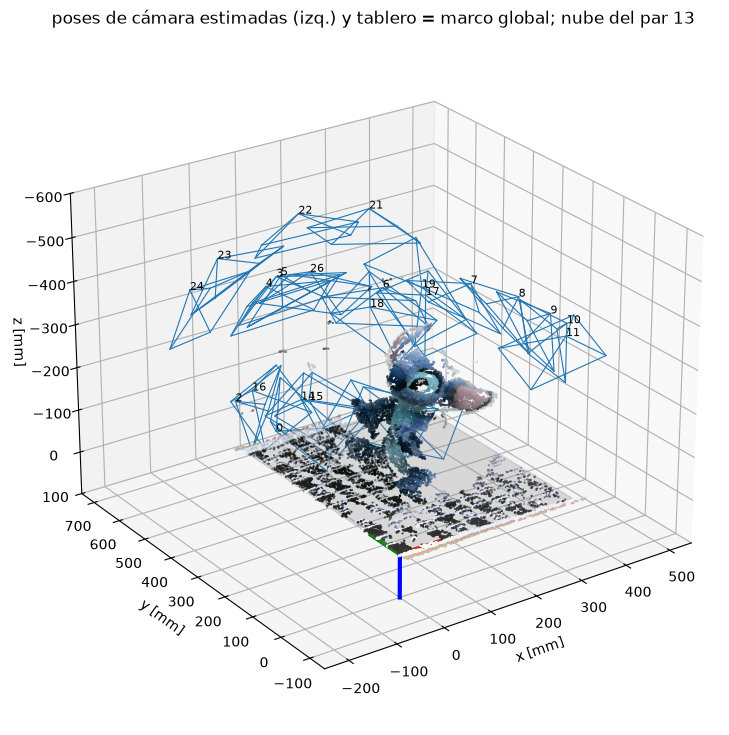

In [15]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from utils import frustum_world

fig = plt.figure(figsize=(11, 9))
ax = fig.add_subplot(projection="3d")

# Tablero
bw, bh = SQUARES[0] * SQUARE_MM, SQUARES[1] * SQUARE_MM
ax.add_collection3d(Poly3DCollection([[(0, 0, 0), (bw, 0, 0), (bw, bh, 0), (0, bh, 0)]], alpha=0.25, color="gray"))

# Cámaras
for v in views:
    c, corners = frustum_world(v, left_K, calibration["image_size"])
    for p in corners:
        ax.plot(*zip(c, p), color="tab:blue", lw=0.8)
    ax.plot(*np.vstack([corners, corners[:1]]).T, color="tab:blue", lw=0.8)
    ax.text(*c, str(v["idx"]), fontsize=8)

# Eje global
for vec, col in zip(np.eye(3) * 100, ["r", "g", "b"]):
    ax.plot(*zip([0, 0, 0], vec), color=col, lw=3)

# Nube del par 13 (solo la zona del tablero)
sub = views[[v["idx"] for v in views].index(13)]
s = np.random.default_rng(0).choice(len(sub["X"]), 60_000, replace=False)
inside = ((sub["X"][s, 2] < 5) & (sub["X"][s, 2] > -350) & (sub["X"][s, 0] > -20) & (sub["X"][s, 0] < 400)
          & (sub["X"][s, 1] > -20) & (sub["X"][s, 1] < 570))
ax.scatter(*sub["X"][s][inside].T, c=sub["C"][s][inside], s=0.3)

ax.set_xlabel("x [mm]")
ax.set_ylabel("y [mm]")
ax.set_zlabel("z [mm]")
ax.set_xlim(-250, 550)
ax.set_ylim(-150, 750)
ax.set_zlim(-600, 100)
ax.invert_zaxis()
ax.view_init(elev=25, azim=-125)
ax.set_title("poses de cámara estimadas (izq.) y tablero = marco global; nube del par 13")
plt.show()

Las cámaras forman una órbita alrededor del tablero, a 20 a 55 cm sobre su plano (z negativo), y eso coincide con
cómo movimos la cámara al capturar.

<div style="text-align: center; font-family: 'Helvetica', sans-serif;">

### **Fusión y optimización de la nube de puntos**
</div>

Acumulamos todas las nubes en el marco global y optimizamos en Open3D:

1. **Caja (filtrado espacial)**: `OrientedBoundingBox` que encierra la zona del peluche sobre el tablero
   (x 40 a 360, y 80 a 500, z de −360 a −4 mm), con `get_point_indices_within_bounding_box` y `select_by_index`.
2. **Submuestreo** `voxel_down_sample(2 mm)`: las ~25 vistas se superponen y hay mucha redundancia.
   2 mm conserva el detalle del pelaje y de las orejas.
3. **Outliers**: `remove_statistical_outlier(30 vecinos, 1,5 σ)` y después `remove_radius_outlier(12 puntos en 6 mm)`
   para puntos flotantes.
4. **Plano del tablero**: `segment_plane` (RANSAC, 10 mm) encuentra el tablero dentro de la caja y lo quitamos para
   quedarnos solo con el objeto.
5. **Componente principal**: `cluster_dbscan` (6 mm) y nos quedamos con el cluster más grande (el peluche), lo que
   descarta restos sueltos.

In [16]:
import open3d as o3d
from utils import to_pcd

pcd_all = to_pcd(np.vstack([v["X"] for v in views]), np.vstack([v["C"] for v in views]))
steps = [("nube global completa", pcd_all)]

# 1. Caja
box = o3d.geometry.AxisAlignedBoundingBox(np.array([40.0, 80.0, -360.0]), np.array([360.0, 500.0, -4.0]))
obb = o3d.geometry.OrientedBoundingBox.create_from_axis_aligned_bounding_box(box)
obb.color = (1, 0, 0)
pcd_box = pcd_all.select_by_index(obb.get_point_indices_within_bounding_box(pcd_all.points))
steps.append(("1. caja", pcd_box))

# 2. Submuestreo
pcd_vox = pcd_box.voxel_down_sample(voxel_size=2.0)
steps.append(("2. voxel 2 mm", pcd_vox))

# 3. Outliers (estadístico + radio)
pcd_stat, _ = pcd_vox.remove_statistical_outlier(nb_neighbors=30, std_ratio=1.5)
pcd_rad, _ = pcd_stat.remove_radius_outlier(nb_points=12, radius=6.0)
steps.append(("3. outliers (estadístico + radio)", pcd_rad))

# 4. Plano del tablero (segment_plane es multihilo: igual puede variar ~1 mm entre corridas)
o3d.utility.random.seed(0)
plane, plane_idx = pcd_rad.segment_plane(distance_threshold=10.0, ransac_n=3, num_iterations=2000)
pcd_obj = pcd_rad.select_by_index(plane_idx, invert=True)
steps.append(("4. sin plano del tablero", pcd_obj))

# 5. Cluster principal
labels = np.array(pcd_obj.cluster_dbscan(eps=6.0, min_points=10))
main = np.bincount(labels[labels >= 0]).argmax()
pcd_final = pcd_obj.select_by_index(np.where(labels == main)[0])
steps.append(("5. cluster principal (final)", pcd_final))

for name, p in steps:
    print(f"{name}: {len(p.points)} puntos")

a, b, c, d = plane
print(f"\nPlano del tablero: {a:.3f}x + {b:.3f}y + {c:.3f}z + {d:.2f} = 0 ({len(plane_idx)} inliers)")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
nube global completa: 9282487 puntos
1. caja: 1510554 puntos
2. voxel 2 mm: 239309 puntos
3. outliers (estadístico + radio): 233096 puntos
4. sin plano del tablero: 180711 puntos
5. cluster principal (final): 175791 puntos

Plano del tablero: -0.006x + -0.001y + 1.000z + 10.44 = 0 (52385 inliers)


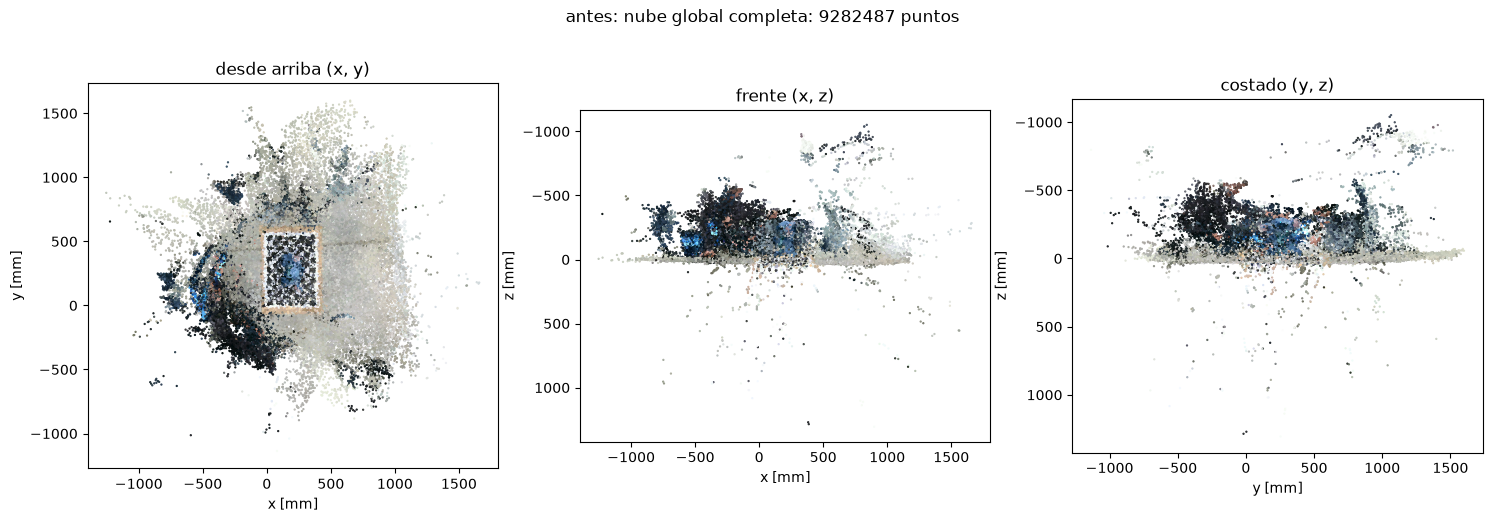

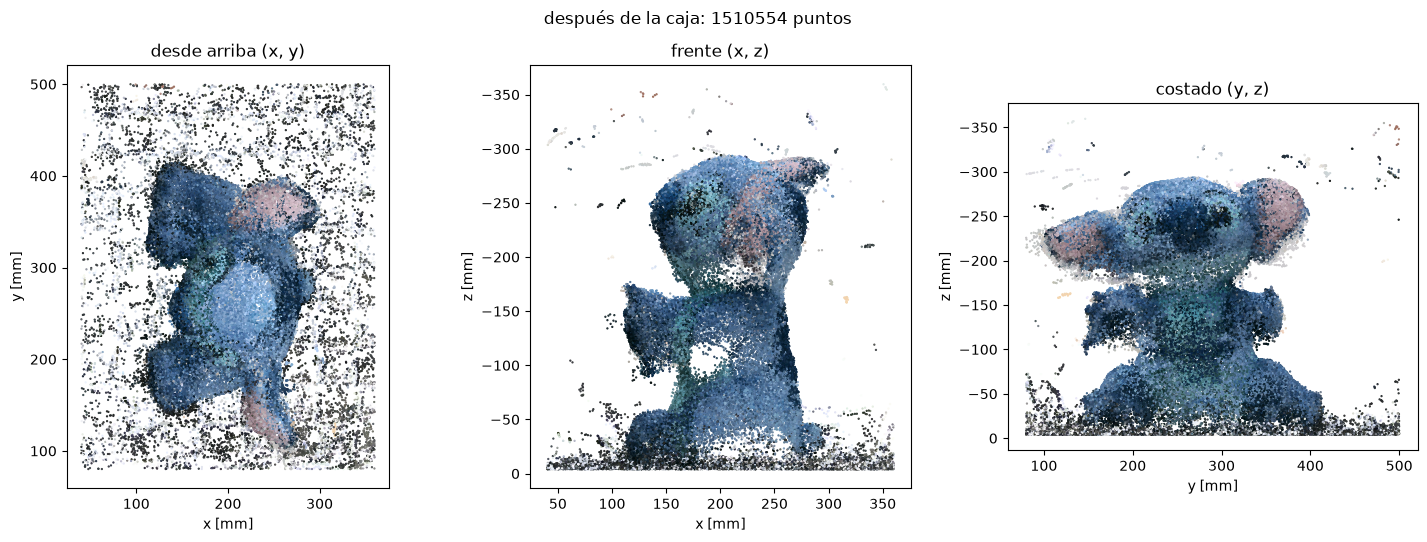

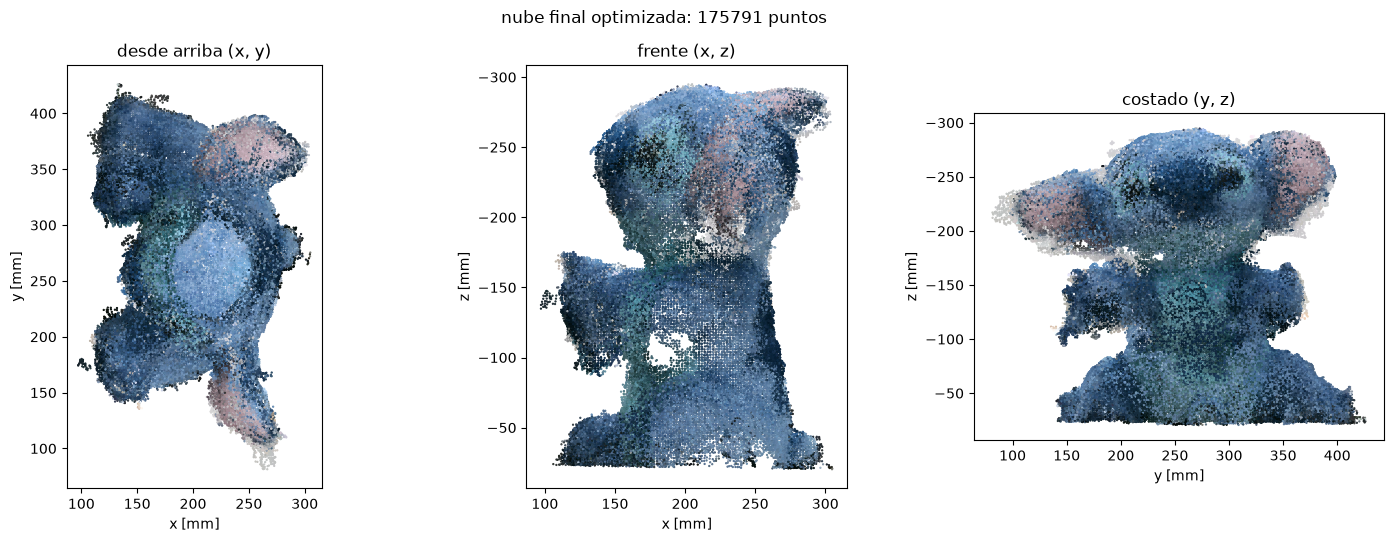

In [17]:
from utils import plot_views

plot_views(steps[0][1], "antes: nube global completa")
plot_views(steps[1][1], "después de la caja")
plot_views(pcd_final, "nube final optimizada")

Exportamos la nube final en formato `.ply` binario.

In [18]:
out_dir = os.path.join(BASE, "outputs")
os.makedirs(out_dir, exist_ok=True)
ply_path = os.path.join(out_dir, "stitch_final.ply")
o3d.io.write_point_cloud(ply_path, pcd_final, write_ascii=False, compressed=False)

print(f"{ply_path}: {os.path.getsize(ply_path) / 1e6:.1f} MB, {len(pcd_final.points)} puntos")

../outputs/stitch_final.ply: 4.7 MB, 175791 puntos


<div style="text-align: center; font-family: 'Helvetica', sans-serif;">

### **Medición métrica**
</div>

Las coordenadas están en **mm reales** porque la escala entra dos veces en el pipeline: en el baseline $B$ de la
calibración estéreo (z = f·B/d) y en el tamaño impreso del tablero (pose PnP). No es structure-from-motion monocular,
donde la reconstrucción queda definida salvo un factor de escala. Además ya verificamos que ambas escalas son
consistentes (casillero triangulado de 42,1 mm frente a 42,0 mm).

- **Alto**: distancia de cada punto al **plano del tablero ajustado** con RANSAC (no al plano z = 0 del PnP; ver la
  nota abajo). Alto = percentil 99,5 de esa distancia, para que un puñado de puntos espurios no lo infle. También
  reportamos el máximo. Entre corridas el resultado varía en ±1 mm (RANSAC).
- **Ancho y profundidad**: como el tablero define ejes horizontales naturales, proyectamos sobre el plano y calculamos
  el rectángulo mínimo (`cv2.minAreaRect`) que encierra el 99 % central de los puntos. El lado largo es el ancho de
  oreja a oreja.

**Nota sobre el plano**: el tablero reconstruido por estéreo aparece entre 7 y 10 mm por encima de z = 0 según la
corrida de RANSAC (es el término `d` del plano). Es un sesgo sistemático entre la profundidad estéreo y la pose del PnP
(≈1,5 % de la distancia de trabajo) y un buen punto para la discusión: viene de errores residuales de calibración
(rectificación con 0,2 a 1,8 px de `dy`). Medir respecto al plano ajustado lo cancela para el alto.

In [19]:
P = np.asarray(pcd_final.points)

# Alto: distancia de cada punto al plano del tablero
n = plane[:3] / np.linalg.norm(plane[:3])
dist_plane = np.abs(P @ n + plane[3] / np.linalg.norm(plane[:3]))
alto_p995 = np.percentile(dist_plane, 99.5)
alto_max = dist_plane.max()

# Ancho y profundidad: rectángulo mínimo sobre el plano (x, y del mundo; la normal del plano es ~ eje z)
xy = P[:, :2].astype(np.float32)
q = np.percentile(xy, [0.5, 99.5], axis=0)
core = np.all((xy >= q[0]) & (xy <= q[1]), axis=1)
(cx, cy), (w_rect, h_rect), ang = cv2.minAreaRect(xy[core])
ancho, prof = max(w_rect, h_rect), min(w_rect, h_rect)

print(f"Normal del plano: {np.round(n, 3)}")
print(f"Alto: {alto_p995:.1f} mm (p99,5), máximo {alto_max:.1f} mm")
print(f"Ancho (orejas): {ancho:.1f} mm")
print(f"Profundidad: {prof:.1f} mm")

# Medidas reales del peluche con regla
REAL_ALTO_MM = 290
REAL_ANCHO_MM = 300
REAL_PROFUNDIDAD_MM = 170
for nombre, est, real in [("alto", alto_p995, REAL_ALTO_MM), ("ancho", ancho, REAL_ANCHO_MM), ("profundidad", prof, REAL_PROFUNDIDAD_MM)]:
    if real:
        print(f"Error relativo del {nombre}: {100 * (est - real) / real:+.1f} % ({est:.1f} vs {real:.1f} mm)")

Normal del plano: [-0.006 -0.001  1.   ]
Alto: 279.7 mm (p99,5), máximo 286.0 mm
Ancho (orejas): 294.0 mm
Profundidad: 172.5 mm
Error relativo del alto: -3.5 % (279.7 vs 290.0 mm)
Error relativo del ancho: -2.0 % (294.0 vs 300.0 mm)
Error relativo del profundidad: +1.4 % (172.5 vs 170.0 mm)


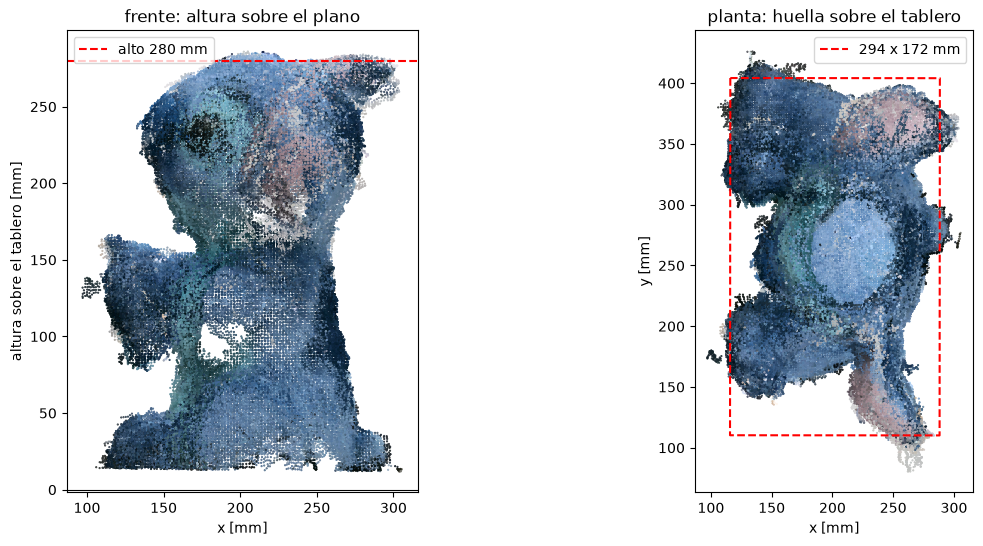

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
Cc = np.asarray(pcd_final.colors)

ax[0].scatter(P[:, 0], dist_plane, c=Cc, s=0.3)
ax[0].axhline(alto_p995, color="r", ls="--", label=f"alto {alto_p995:.0f} mm")
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_aspect("equal")
ax[0].legend()
ax[0].set_title("frente: altura sobre el plano")
ax[0].set_xlabel("x [mm]")
ax[0].set_ylabel("altura sobre el tablero [mm]")

ax[1].scatter(P[:, 0], P[:, 1], c=Cc, s=0.3)
box_pts = cv2.boxPoints(((cx, cy), (w_rect, h_rect), ang))
ax[1].plot(*np.vstack([box_pts, box_pts[:1]]).T, "r--", label=f"{ancho:.0f} x {prof:.0f} mm")
ax[1].set_aspect("equal")
ax[1].legend()
ax[1].set_title("planta: huella sobre el tablero")
ax[1].set_xlabel("x [mm]")
ax[1].set_ylabel("y [mm]")
plt.show()

<div style="text-align: center; font-family: 'Helvetica', sans-serif;">

### **Visualización interactiva en Open3D (opcional)**
</div>

Abre ventanas de Open3D con el marco global, los frustums de cada cámara (`LineSet.create_camera_visualization`), la
caja de recorte y la nube. No corre en Colab ni sin pantalla: dejamos `SHOW_3D = False` para ejecutar el notebook de
punta a punta.

In [21]:
SHOW_3D = False

if SHOW_3D:
    w, h = calibration["image_size"]
    geoms = [o3d.geometry.TriangleMesh.create_coordinate_frame(size=100)]
    for v in views:
        extr = np.eye(4)
        extr[:3, :3] = v["R_wc"]
        extr[:3, 3] = v["t_wc"]
        cam = o3d.geometry.LineSet.create_camera_visualization(w, h, left_K, extr, scale=60)
        cam.paint_uniform_color([0.1, 0.3, 0.9])
        geoms.append(cam)

    # Nube global (submuestreada para que sea fluida) + caja de recorte
    o3d.visualization.draw_geometries(geoms + [pcd_all.voxel_down_sample(4.0), obb],
                                      window_name="poses de cámara y nube global")
    o3d.visualization.draw_geometries([pcd_final, o3d.geometry.TriangleMesh.create_coordinate_frame(size=50)],
                                      window_name="nube final optimizada")